# SNP ordering and layout

**Question:** Can changing the SNP-to-qubit order reduce two-qubit gates or improve noisy samples?

I compare automatic layout with the original and a selected SNP order on the same fixed layout. The fixed-layout pair changes only SNP placement. The same reads, angles, objective, backend, seeds and shots are used throughout.

To keep the search small, I compile a few candidate orders using separate discovery seeds. The compiler evaluates the candidates on the chosen backend.

## 1. Load the shared problem

This runs [the setup notebook](hardware_setup.ipynb), which explains the data, circuit and score. Set the inputs there before running this notebook.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware_experiments/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('docs/hardware_experiments/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


## 2. Select a few candidate orders

I try the original order and up to seven random orders. Each is compiled with the same two discovery seeds. To make a useful comparison, I select the best *different* order by median two-qubit count, using two-qubit depth to break ties. The original may still rank first. This small search does not guarantee the best order.

In [ ]:
physical = list(range(n))
discovery_seeds = [1001, 1002]
assert not set(discovery_seeds) & set(compile_seeds)
rng = np.random.default_rng(17)
candidates = [tuple(range(n))]
for _ in range(100):
    proposal = tuple(int(i) for i in rng.permutation(n))
    if proposal not in candidates:
        candidates.append(proposal)
    if len(candidates) == 8:
        break
print('Candidate orders:', candidates)
print('Discovery compilations:', len(candidates) * len(discovery_seeds))

Candidate orders: [(0, 1, 2, 3, 4), (4, 0, 2, 1, 3), (4, 0, 1, 3, 2), (2, 4, 0, 3, 1), (3, 0, 2, 4, 1), (0, 2, 4, 3, 1), (3, 1, 0, 2, 4), (3, 2, 0, 1, 4)]
Discovery compilations: 16


In [3]:
discovery_rows = []
for candidate in candidates:
    for seed in discovery_seeds:
        manager = generate_preset_pass_manager(
            backend=backend, optimization_level=2, initial_layout=physical,
            routing_method='sabre', seed_transpiler=seed,
        )
        compiled_candidate = manager.run(make_circuit(candidate))
        discovery_rows.append({'order': candidate, 'seed': seed, **resources(compiled_candidate)})
discovery = pd.DataFrame(discovery_rows)
ranking = discovery.groupby('order', sort=False)[['2q gates', '2q depth']].median()
ranking = ranking.sort_values(['2q gates', '2q depth'], kind='stable')
alternatives = [candidate for candidate in ranking.index if candidate != tuple(range(n))]
order = alternatives[0] if alternatives else tuple(range(n))
display(ranking)
print('Selected order:', order)

,2q gates,2q depth
order,,
"(0, 1, 2, 3, 4)",26.0,21.0
"(3, 1, 0, 2, 4)",29.0,22.0
"(4, 0, 2, 1, 3)",31.0,24.0
"(3, 2, 0, 1, 4)",35.0,26.0
"(2, 4, 0, 3, 1)",36.0,26.0
"(4, 0, 1, 3, 2)",39.0,27.0
"(0, 2, 4, 3, 1)",39.0,29.0
"(3, 0, 2, 4, 1)",41.0,29.0


Selected order: (3, 1, 0, 2, 4)


Each order must still describe the same problem. For this small example, I check the full ideal output distribution after mapping measurements back to the original SNP bits.

In [4]:
circuits = {
    'Automatic': make_circuit(),
    'Original order': make_circuit(),
}
if tuple(order) != tuple(range(n)):
    circuits['Selected order'] = make_circuit(order)
else:
    print('The selected order matches the original; no duplicate arm is added.')
if ideal is not None:
    for circuit in circuits.values():
        assert np.allclose(logical_probabilities(circuit), ideal)
    print('Ideal distributions agree for all tested circuits.')

Ideal distributions agree for all tested circuits.


## 3. Compile with the same seeds

The automatic arm lets Qiskit choose its layout. The other two arms use the same physical subset. I count native two-qubit gates, two-qubit depth and total depth after compilation.

In [5]:
compiled = {}
rows = []
for name, circuit in circuits.items():
    layout = None if name == 'Automatic' else physical
    for seed in compile_seeds:
        manager = generate_preset_pass_manager(
            backend=backend, optimization_level=2,
            initial_layout=layout, routing_method='sabre', seed_transpiler=seed,
        )
        compiled[name, seed] = manager.run(circuit)
        rows.append({'method': name, 'seed': seed, **resources(compiled[name, seed])})
resource_table = pd.DataFrame(rows)
display(resource_table.groupby('method', sort=False)[['2q gates', '2q depth', 'depth']]
        .agg(['median', 'min', 'max']))

2q gates         2q depth          depth        
                 median min max   median min max median min max
method                                                         
Automatic          27.0  27  29     22.0  22  24   46.0  46  51
Original order     28.0  26  28     23.0  21  23   57.0  57  57
Selected order     28.0  28  30     21.0  21  23   48.0  48  49

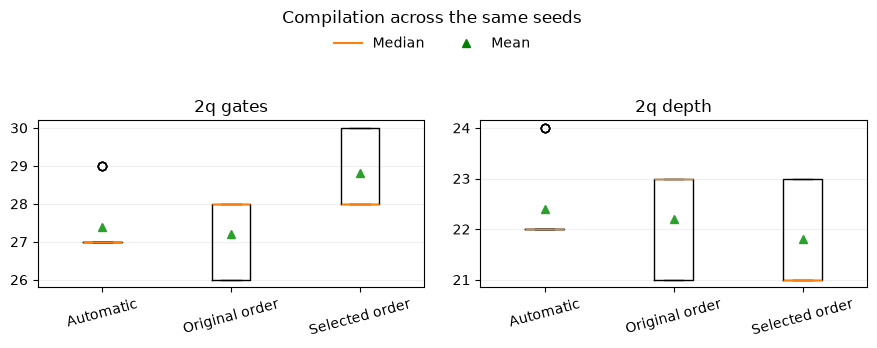

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, metric in zip(axes, ['2q gates', '2q depth']):
    data = [resource_table.loc[resource_table.method == name, metric] for name in circuits]
    ax.boxplot(data, tick_labels=circuits.keys(), showmeans=True)
    ax.set_title(metric)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Compilation across the same seeds')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 4. Sample several compiled circuits

I use the first three compiled seeds and repeat each noisy simulation three times. This is a small pilot, not a confidence interval or a real-device result. Turn `run_noise` off for a resource-only study.

In [7]:
run_noise = True
if run_noise:
    if backend.num_qubits > 16:
        raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    samples = []
    for name in circuits:
        for seed in noise_seeds:
            for repeat in range(noise_repeats):
                counts = simulator.run(
                    compiled[name, seed], shots=shots,
                    seed_simulator=9000 + seed * 100 + repeat,
                ).result().get_counts()
                samples.append({'method': name, 'seed': seed, 'repeat': repeat, **score(counts)})
    noisy_results = pd.DataFrame(samples)
    display(noisy_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
            .agg(['mean', 'std']))

mean cost           optimum frequency          
                    mean       std              mean       std
method                                                        
Automatic       9.439290  0.056293          0.275933  0.005655
Original order  9.541992  0.211669          0.279514  0.011511
Selected order  9.373210  0.178497          0.281467  0.009760

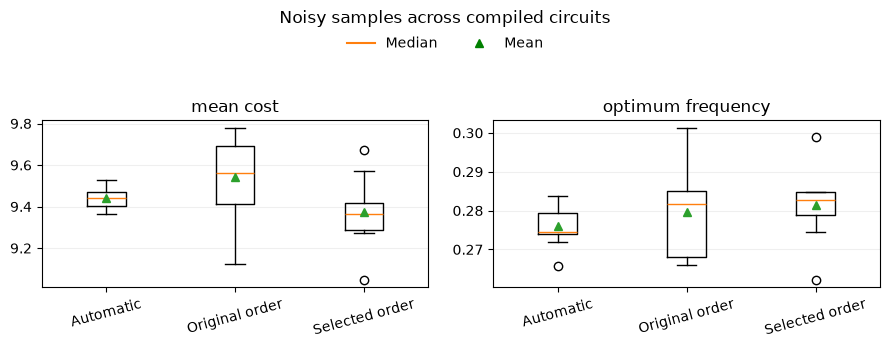

In [8]:
if run_noise:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
        values = [noisy_results.loc[noisy_results.method == name, metric] for name in circuits]
        ax.boxplot(values, tick_labels=circuits.keys(), showmeans=True)
        ax.set_title(metric)
        ax.tick_params(axis='x', rotation=15)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Noisy samples across compiled circuits')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

## What did I find?

In the saved run, the selected SNP order had the same median two-qubit gate count as the original order (28), but a lower median two-qubit depth (21 instead of 23). Its noisy mean cost was slightly lower, while optimum frequency was similar. Automatic layout is a separate comparison because the compiler also chooses the placement.

This is a small search on one problem; the noisy test uses only three compiled seeds. If I change the input or rerun the experiment, I need to revisit this conclusion.